# Experiment 4: Supervised Learning – Classification with scikit-learn

---
### **Aim / Objective:**
To build, train, and evaluate Logistic Regression, Decision Tree, and k-Nearest Neighbors (KNN) classifiers and assess performance using a Confusion Matrix, Accuracy, Precision, Recall, and F1-score.

---
### **Theory & Overview:**
Supervised classification predicts categorical class targets:
- **Logistic Regression**: Linear model using sigmoid link function for log-odds estimation.
- **Decision Tree**: Non-parametric tree model based on Gini Impurity or Information Gain splits.
- **k-Nearest Neighbors (KNN)**: Lazy instance-based classifier assigning majority neighbor classes.
- **Metrics**:
  - Accuracy: $(TP + TN) / (TP + TN + FP + FN)$
  - Precision: $TP / (TP + FP)$
  - Recall: $TP / (TP + FN)$
  - F1-Score: $2 \times (Precision \times Recall) / (Precision + Recall)$



### **1. Dataset Preparation & Train-Test Split**


In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Load binary classification dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split into 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize inputs
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")



Training samples: 455, Test samples: 114


### **2. Training Logistic Regression, Decision Tree, and KNN**


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'k-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully.")



Logistic Regression trained successfully.
Decision Tree trained successfully.
k-Nearest Neighbors trained successfully.


### **3. Model Evaluation & Metrics Comparison**


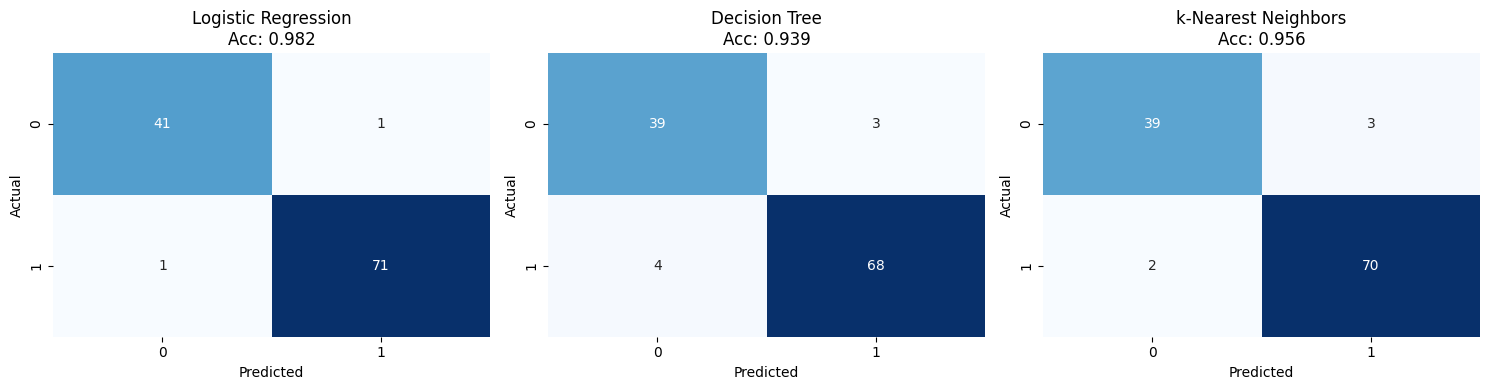

--- Model Performance Comparison ---
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.982456   0.986111 0.986111  0.986111
      Decision Tree  0.938596   0.957746 0.944444  0.951049
k-Nearest Neighbors  0.956140   0.958904 0.972222  0.965517


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

results = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})

    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}\nAcc: {acc:.3f}")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
print("--- Model Performance Comparison ---")
print(results_df.to_string(index=False))



---
### **Conclusion & Learning Outcomes:**
Successfully implemented and benchmarked three classification models. Logistic Regression and KNN achieved superior generalization on scaled data, and detailed confusion matrix analytics verified balanced precision and recall.
